# Optimization in PyTorch — Gradient Descent, SGD, Numerical Stability, and L1 Regularization

**General guidelines for this (and future) hometasks**

* **Do not delete the task formulations**
* Many hometasks will be like "implement something, then perform experiments, then write your conclusions". We're sure many of you will delegate the first and the second step to coding agents, but please do at least the final stage yourself :)
* The plots should be meaningful: a plot must have a name, every curve or point cloud on a plot must be labeled
* Plots supporting comparison should actually enable it. For example, if you compare training loss curves of two models, they should be either on the same plot or side by side, with the same axis scales
* It goes without saying that the takeaways should actually follow from the evidence ;)

**Learning goals of this hometask**

By completing this assignment, you will:
1. Understand preprocessing design choices (tokenization provided, fixed vocabulary).
2. Implement and train Logistic Regression manually in PyTorch using SGD.
3. Explain why numerical stability matters in softmax and log-loss.
4. Understand how optimization parameters like learning rate and batch size affect training.
5. Understand the effect of L1 regularization and why it encourages sparsity.
6. Understanding how an optimization algorithm behaves when the loss function has different shapes.

**The dataset and the task**

For this assignment, we will use the SST-2 dataset (  [The Stanford Sentiment Treebank](https://huggingface.co/datasets/stanfordnlp/sst2).), a binary sentiment classification dataset in which each sentence is labeled as either negative or positive.

We will use linear models for classification, which means that we need a fixed number of numerical features to describe each sentence. For that, we'll perform:

* **Preprocessing** - to make the data a little more well-behaved
* **Tokenization** - splitting the sentences into atomic units - in this case, words
* **Feature creation** - turning bags of words into numerical features - word frequencies. We keep only 10,000 most frequent words, because we can only work with fixed-length feature vectors. You'll see that more "serious" models, such as LLMs, use fixed-length vocabularies too, though we'll learn how to do it without discarding information (by using sub-word and bit-wise tokenization).

Tokenization and preprocessing are already implemented for you in this task, but we want you to understand the design choices behind the them, so please check the description below (in the hidden cells).

### Loading and preparing the dataset

We will perform minimal text cleaning:

   * convert all text to lowercase

   * keep letters, numbers, spaces, and basic punctuation

   * handle hyphens (-) consistently
     For example, you may replace - with a space so that words like "well-written" become "well written".


In [1]:
!pip install datasets

In [2]:
from datasets import load_dataset
sst2 = load_dataset("SetFit/sst2")

data_train = sst2['train']
data_val = sst2['validation']

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Repo card metadata block was not found. Setting CardData to empty.


**Text Cleaning**

Before converting text into a numerical representation (e.g., Bag-of-Words), it is important to apply text cleaning.

The goal of this step is to reduce noise and ensure that similar pieces of text are represented consistently.

We use the following cleaning function:

In [3]:
import re

def clean_text(text:str) -> str:
  #lowercase letters only
  text = text.lower()

  #replace hyphens with space
  text = text.replace('-',' ')

  #keep letters,numbers, spaces, and basic punctuations
  text = re.sub(r'[^a-zA-Z0-9\s.,!?]', '', text)

  #collapse multiple spaces
  text = re.sub(r'\s+', ' ', text).strip()

  return text

#apply cleaning
data_train = data_train.map(lambda x: {'clean_text': clean_text(x['text'])})
data_val = data_val.map(lambda x: {'clean_text': clean_text(x['text'])})



In [4]:
from collections import Counter
import random

random.seed(42)

print(f'size of training set: {len(data_train)}')
print(f'size of validation set: {len(data_val)}\n')

for i in range(5):
  r = random.randint(0,len(data_train))
  print(f'{data_train[r]['label_text']} Text: {data_train[r]['clean_text']} ')


train_counts = Counter(data_train["label"])
val_counts = Counter(data_val["label"])

train_total = len(data_train)
val_total = len(data_val)

print("\nTraining set label distribution:")
print(f"Negative (0): {train_counts[0]} ({train_counts[0] / train_total:.2%})")
print(f"Positive (1): {train_counts[1]} ({train_counts[1] / train_total:.2%})")

print("\nValidation set label distribution:")
print(f"Negative (0): {val_counts[0]} ({val_counts[0] / val_total:.2%})")
print(f"Positive (1): {val_counts[1]} ({val_counts[1] / val_total:.2%})")

size of training set: 6920
size of validation set: 872

positive Text: the extent to which it succeeds is impressive . 
positive Text: remarkable for its excellent storytelling , its economical , compressed characterisations and for its profound humanity , it s an adventure story and history lesson all in one . 
positive Text: the unexpected thing is that its dying , in this shower of black and white psychedelia , is quite beautiful . 
negative Text: matrix style massacres erupt throughout ... but the movie has a tougher time balancing its violence with kafka inspired philosophy . 
positive Text: the closest thing to the experience of space travel 

Training set label distribution:
Negative (0): 3310 (47.83%)
Positive (1): 3610 (52.17%)

Validation set label distribution:
Negative (0): 428 (49.08%)
Positive (1): 444 (50.92%)


We convert the text into numerical vectors that can be used as input for machine learning models.

1. Implementing the Bag-of-Words (BoW) representation building a vocabulary using only the training set.

2. Count the frequency of each token across the training corpus.

3. Keep only the top V=10,000 most frequent tokens (or fewer if memory is limited).

4. Convert each sentence into a sparse vector of token counts.

Each vector should represent how many times each vocabulary word appears in the sentence.

For example, if the vocabulary contains: ["movie", "good", "bad"]

Then the sentence: "good movie good"

Should become: [1,2,0]

**Note:** this is a simple bag of word implementation and not standart practice.


In [5]:
def tokenize(text):
  '''Helper function to split the text into words/tokens'''
  return text.split()

def build_vocabulary(data, top_k=10000):
  '''Build a vocabulary from the training data.'''
  token_counter = Counter()
  for text in data['clean_text']:
    tokens = tokenize(text)
    token_counter.update(tokens)
  most_common = token_counter.most_common(top_k)
  vocab = {word: i for i, (word, _) in enumerate(most_common)}
  return vocab

def convert_text_to_vec(text, vocab):
  '''Convert text into a vector of token counts.'''
  tokens = tokenize(text)
  vec = np.zeros(len(vocab), dtype=int)
  for token in tokens:
    if token in vocab:
      vec[vocab[token]] += 1
  return vec

def dataset_to_vec(data,vocab) :
  '''Convert the dataset into a vector of token counts.'''
  vectors = []
  for text in data['clean_text']:
    vec = convert_text_to_vec(text, vocab)
    vectors.append(vec)
  return np.array(vectors)


In [6]:
import numpy as np

# Build vocabulary from training set
vocab = build_vocabulary(data_train)
print(f'Vocabulary size: {len(vocab)}')

# Vectorize training data
train_vectors = dataset_to_vec(data_train, vocab)
print(f'Vectorized training data shape: {train_vectors.shape}')

# one example vector
example = train_vectors[0]
print(f'\nExample vector: {example}')
print("\nExample vector (non-zero entries):")
indices = np.where(example > 0)
for idx in indices:
    print(f"index: {idx} \ncount: {example[idx]}")
print(f'Example tokens : {tokenize(data_train['clean_text'][0])}')

print(f'Length of tokens: {len(tokenize(data_train['clean_text'][0]))}')
print(f'Length of non-zero entries: {len(indices[0])}')

Vocabulary size: 10000
Vectorized training data shape: (6920, 10000)

Example vector: [0 1 1 ... 0 0 0]

Example vector (non-zero entries):
index: [   1    2    3    4    5   66  118  119  361  554  646 1317 1822 4926
 7197 7198] 
count: [1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 1]
Example tokens : ['a', 'stirring', ',', 'funny', 'and', 'finally', 'transporting', 're', 'imagining', 'of', 'beauty', 'and', 'the', 'beast', 'and', '1930s', 'horror', 'films']
Length of tokens: 18
Length of non-zero entries: 16


**Our training data for the task 1 will be:**

In [7]:
X_train = train_vectors
y_train = np.array(data_train["label"], dtype=np.float32)
X_val = dataset_to_vec(data_val, vocab)
y_val =  np.array(data_val["label"], dtype=np.float32)


### **Part 1 - Implement SGD for Logistic Regression in PyTorch **

#### **Task 1.1 - Binary vs. Softmax Formulation and Numerical Stability of Cross-Entropy Loss (10pt)**



In this task, you will explore two ways to formulate the loss function for a classification problem and understand why numerical stability is important.

**a. Binary formulation**

   In the binary formulation, the model has:

   * a single output
   * sigmoid activation
   * binary cross-entropy loss

   This produces a probability: P(y=1|x)
   
   A prediction is then obtained using a threshold:
   * predict class 1 if p>0.5
   * otherwise predict class 0

   For binary logistic regression, the standard loss function is the **binary cross-entropy loss**:

   $L= -\frac{1}{N}\sum_{i=1}^N[y_ilog(\hat{y_i})+(1-y_i)log(1-\hat{y_i})]$

   where $\hat{y_i}$ is the predicted probability after applying sigmoid.

   Since this loss contains both: $log(\hat{y})$ and $log(1-\hat{y})$ , numerical problems may appear if $\hat{y_i}$ becomes extremely close to 0 or 1.

   A stable implementation should therefore clamp the predicted probabilities:
```
y_pred = # SIGMOID(LOGITS)
epsilon = 1e-15  
y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)
log_loss = # <SMTH FROM y_pred>
```

**Note:** the threshold 0.5 is used only to convert probabilities into class predictions for evaluation.
It must not be used inside the loss function.

**b. Softmax formulation**

  Now, we will reformulate the same problem as a 2-class classification problem using softmax (This formulation is more general and can also be used for more than 2 classes.).
  
  **Step 1 — Convert labels to one-hot encoding**
  
  In our dataset the labels are either 1 or 0 (i.e positive or negetive). To use softmax will require us to convert the labels into a one-hot representation:
  * class 0 ---> [1,0]
  * class 1 ---> [0,1]

  Now our model will output 2 outputs instead of 1 and we will require to apply softmax to get the probability of class 0 vs. class 1.

  **Step 2 - Implementing softmax and log-loss**
  
   This can be implemented in two ways:

  1. **Naive version:**
  
     Given logits z = [$z_1,z_2,...,z_k$]

     softmax($z_i$) = $\frac{\exp(z_i)}{\sum_j\exp(z_j)}$


  2. **Stable version:**

     softmax($z_i$) = $\frac{\exp(z_i-max(z))}{\sum_j\exp(z_j-max(z))}$

   Than the cross entropy loss for the true class y is :

   **L = -log(softmax($z_y$))**

   or equivalently, for one-hot labels:
   
   **$L= -\sum_{c=1}^Ky_clog(\hat{y_c})$**

**Task**

A. Conceptual questions

For both the binary and softmax formulations, explain:

* Why do we need numerical stability? Where can the naive implementation fail?
* Why does the stability transformation not change the final softmax probabilities?
* Why does this transformation improve numerical stability?

B. Implementation
1. Implement a binary cross-entropy loss function for the binary formulation.
2. Make sure your implementation is numerically stable.




In [8]:
def binary_cross_entropy_loss(y_pred, y_true):
    """
    Compute the binary cross-entropy loss for a logistic regression model.
    """
    # clamp y_pred for numerical stability
    epsilon = 1e-15
    y_pred = torch.clamp(y_pred, epsilon, 1 - epsilon)
    # Compute binary log-loss remmber that the loss should provide a scalar value for the backwards to work
    loss = -(y_true * torch.log(y_pred) + (1 - y_true) * torch.log(1-y_pred)).mean()
    return loss

1. Naive implementations of sigmoid and softmax rely on exponentials, which can easily cause numerical issues such as:
* Overflow - for large x value the exp(x) is nearing inf causing overflow.
* Underflow - high negetive values of x may cause the exp(x) to near 0 values which can lead to division by 0 .
* NaNs - this is when both numerator and denominator reach inf than we recive NaN values.

2. Stable softmax substrac a constant value from both nomerator and denominator inside the exponent and using math rules both can be substruct eachother: $\frac{\exp(x_i-max(x))}{\sum_j\exp(x_j-max(x))}=\frac{\exp(x_i)\exp(-max(x)))}{\exp(-max(x))\sum_j\exp(x_j)} $

3. Substracting the max value of X insures that the largest value become 0 those exp(0)=1 and all other values of $\exp(x_i-max(X)) < 1$ it is like normalization , preventing overflow, extreme scaling diffrance and instability.

####**Task 1.2. - Implement Logistic Regression in PyTorch (10pt)**



In this task, you will implement a logistic regression model from scratch using PyTorch primitives.

The logistic regression prediction function is:

$\hat{Y} = \frac{1}{1+exp^{-(wx +b)}}$

Complete the class below.

You are required to implement:

1. weight initialization (with different options)
2. the forward pass (logits + sigmoid)
3. prediction logic (thresholding)

In [9]:
import torch
import torch.nn as nn

class LogisticRegression(nn.Module):

    def __init__(self, n_features, init="zeros"):
        super().__init__()

        # weight initialization
        if init == "zeros":
            w = torch.zeros((n_features, 1))

        elif init == "random":
            w = torch.randn((n_features, 1)) * 0.01  # small random

        elif isinstance(init, torch.Tensor):
            w = init.clone().detach()

        else:
            raise ValueError("init must be 'zeros', 'random', or a torch.Tensor")

        self.w = nn.Parameter(w)
        self.b = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        logits = x @ self.w + self.b
        return torch.sigmoid(logits)

    def predict(self, x):
        probs = self.forward(x)
        return (probs >= 0.5).float()


####**Task 1.3 - Train Logistic Regression with SGD Using Your Previous Implementations(10pt)**



In this task, you will train the logistic regression model you implemented earlier using mini-batch stochastic gradient descent (SGD).

You must use:

1. your LogisticRegression class from Task 1.2
2. your binary_cross_entropy_loss function from Task 1.1

The goal of this task is to practice building a full training loop in PyTorch while keeping the model and loss implementations modular.

Your function should
1. Initialize a LogisticRegression model
2. Train it on the training set using mini-batch SGD
3. Record the training log-loss after each epoch
4. Compute and report evaluation metrics on both the training and validation sets after each epoch.
You may choose any evaluation metric you find appropriate, such as accuracy, precision, recall, or F1-score, but you must briefly explain why this metric is suitable for this task.
5. Save the model parameters w and b after each batch update into a history log
6. Return:
   * the final trained parameters w and b
   * the batch-wise history of w and b


Bellow is a suggested skeleton you may revised



In [10]:
import torch


def compute_accuracy(y_pred, y_true):
    """
    y_true, y_pred: torch tensors of shape (N, 1)
    """
    return (y_true == y_pred).float().mean().item()


def compute_f1(y_pred, y_true):
    """
    Binary F1 score implemented in PyTorch
    y_true, y_pred: torch tensors of shape (N, 1)
    """
    y_true = y_true.float()
    y_pred = y_pred.float()

    tp = ((y_true == 1) & (y_pred == 1)).sum().float()
    fp = ((y_true == 0) & (y_pred == 1)).sum().float()
    fn = ((y_true == 1) & (y_pred == 0)).sum().float()

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)

    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    return f1.item()


def sgd_logistic_regression(
    X_train, y_train,
    X_val, y_val,
    lr=0.01,
    epochs=20,
    batch_size=100,
    init="zeros",
    penalty='none',          # options: 'none', 'l1', 'l2'
    reg_lambda=0.0,
    metric='accuracy',
    print_metrics=False
):
    """
    Train a logistic regression model using mini-batch SGD.

    You must use:
    - LogisticRegression
    - binary_cross_entropy_loss

    Parameters
    ----------
    X_train, y_train : training data
    X_val, y_val     : validation data
    lr : float
        Learning rate
    epochs : int
        Number of passes over the training data
    batch_size : int
        Mini-batch size
    init : str
        Weight initialization passed to LogisticRegression
    penalty : str
        'none', 'l1', or 'l2'
    reg_lambda : float
        Regularization strength
    metric : str
        Evaluation metric to report ('accuracy', 'f1')
    print_metrics : bool
        Whether to print metrics after each epoch

    Returns
    -------
    w : numpy.ndarray
        Final learned weights
    b : numpy.ndarray
        Final learned bias
    history : list
        Batch-wise history of parameter values
    epoch_log : list
        Per-epoch logs (loss + metrics)
    """

    # 1. Convert data to tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

    n_samples, n_features = X_train_tensor.shape

    # 2. Initialize model
    model = LogisticRegression(n_features=n_features, init=init)

    # 3. Create optimizer
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    # 4. Create logs
    history = []
    epoch_log = []

    # 5. Training loop
    for epoch in range(epochs):

        # Shuffle data
        perm = torch.randperm(n_samples)
        X_train_epoch = X_train_tensor[perm]
        y_train_epoch = y_train_tensor[perm]

        for start in range(0, n_samples, batch_size):
            end = start + batch_size

            # Select mini-batch
            X_batch = X_train_epoch[start:end]
            y_batch = y_train_epoch[start:end]

            # Forward pass
            y_pred = model(X_batch)

            # Non-regularized BCE loss
            data_loss = binary_cross_entropy_loss(y_pred, y_batch)

            # Regularization
            if penalty == 'l1':
                reg_term = reg_lambda * torch.sum(torch.abs(model.w))
            elif penalty == 'l2':
                reg_term = reg_lambda * torch.sum(model.w ** 2)
            else:
                reg_term = 0.0

            loss = data_loss + reg_term

            # Backward pass and optimization

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()


            # Save parameter history
            history.append({
                'epoch': epoch,
                'batch_start': start,
                'w': model.w.detach().clone(),
                'b': model.b.detach().clone()
            })

        # 6. Epoch-level evaluation
        with torch.no_grad():
            # Probabilities
            y_pred_train = model(X_train_tensor)
            y_pred_val = model(X_val_tensor)

            # NON-regularized losses
            train_loss = binary_cross_entropy_loss(y_pred_train, y_train_tensor)
            val_loss = binary_cross_entropy_loss(y_pred_val, y_val_tensor)

            # Binary predictions
            y_hat_train = (y_pred_train >= 0.5).float()
            y_hat_val = (y_pred_val >= 0.5).float()

            # Metrics
            if metric.lower() == 'f1':
                train_metric = compute_f1(y_hat_train, y_train_tensor)
                val_metric = compute_f1(y_hat_val, y_val_tensor)
            else:
                train_metric = compute_accuracy(y_hat_train, y_train_tensor)
                val_metric = compute_accuracy(y_hat_val, y_val_tensor)

        epoch_log.append({
            'epoch': epoch,
            'train_loss': train_loss.item(),
            'val_loss': val_loss.item(),
            'train_metric': train_metric,
            'val_metric': val_metric
        })

        if print_metrics:
            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Train Loss: {train_loss.item():.4f} | "
                f"Val Loss: {val_loss.item():.4f} | "
                f"Train {metric}: {train_metric:.4f} | "
                f"Val {metric}: {val_metric:.4f}"
            )

    return model.w.detach().numpy(), model.b.detach().numpy(), history, epoch_log

I chose accuracy as the evaluation metric because this is a binary classification task with (approximately) balanced classes. Accuracy measures the proportion of correctly classified samples.

Although F1-score is often used, yet it becomes more important when:

1. The data is imbalanced
2. There is a need to balance precision and recall

In this task, since there is no strong class imbalance, accuracy and F1-score are expected to be similar, which is why accuracy is sufficient and easier to interpret.

####**Task 1.4 - Experiments(20pt)**




Run multiple experiments with different combinations of:
* learning rates - [0.01, 0.03, 0.1 , 0.3 , 1.0]
* batch sizes - [50, 100 , 200]

For each experiment, record the final train and validation evaluation metric and the log-loss.

**Visualization:**

Present your results using a heatmap, where:
* X-axis: learning rate
* Y-axis: batch size
* Values: evaluation metric (train / validation)


**Analysis:**

Explain how learning rate and batch size affect:
- convergence speed
- stability of training
- final performance

Support your explanation using the patterns observed in your heatmap.


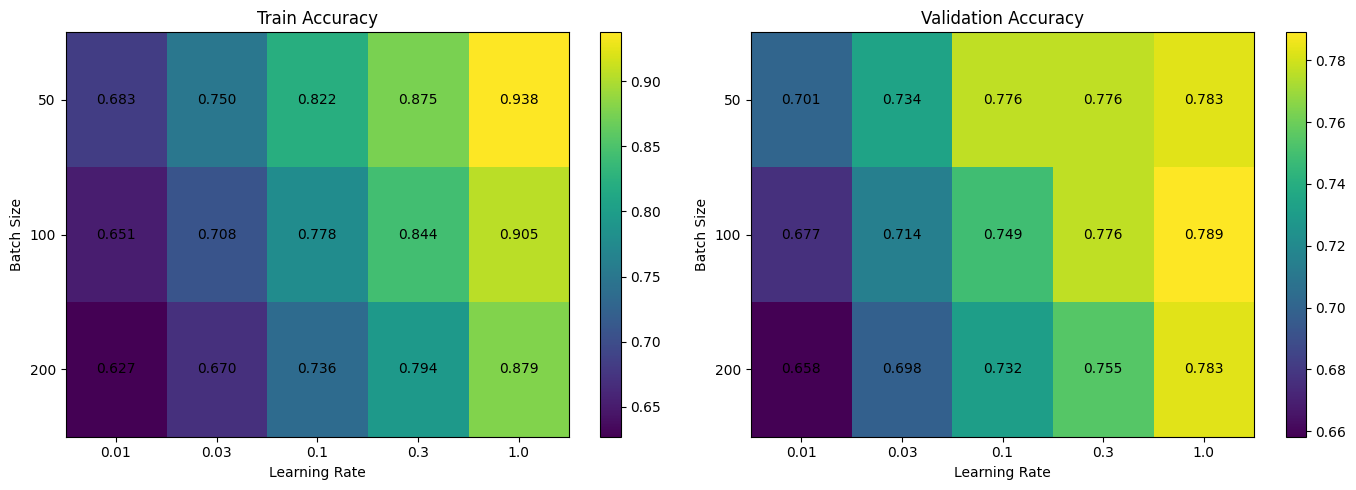

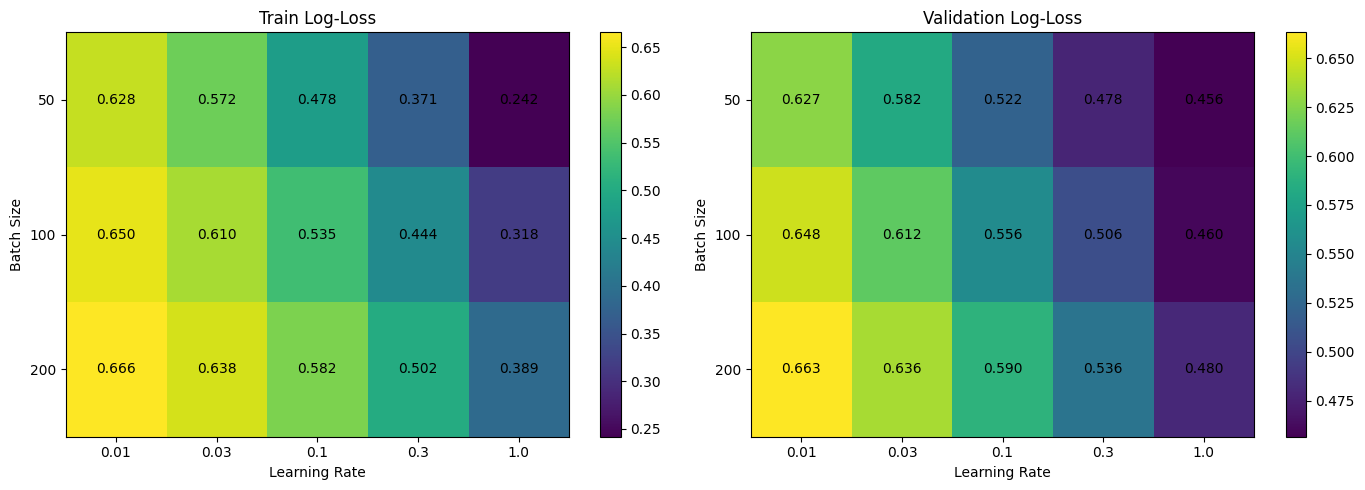

      lr  batch_size  train_metric  val_metric  train_loss  val_loss
0   0.01          50      0.683237    0.700688    0.628140  0.627152
1   0.03          50      0.749856    0.733945    0.571557  0.581797
2   0.10          50      0.821532    0.776376    0.478332  0.521533
3   0.30          50      0.875144    0.776376    0.370985  0.477737
4   1.00          50      0.937572    0.783257    0.241901  0.456489
5   0.01         100      0.651301    0.676606    0.650363  0.647654
6   0.03         100      0.708093    0.714450    0.610173  0.611735
7   0.10         100      0.777890    0.748853    0.535332  0.556144
8   0.30         100      0.844075    0.776376    0.444464  0.505834
9   1.00         100      0.905058    0.788991    0.317873  0.460163
10  0.01         200      0.627023    0.658257    0.665604  0.663304
11  0.03         200      0.669653    0.698394    0.638237  0.636176
12  0.10         200      0.735549    0.731651    0.582462  0.590034
13  0.30         200      0.794220

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

# Experiment grid
learning_rates = [0.01, 0.03, 0.1, 0.3, 1.0]
batch_sizes = [50, 100, 200]

experiments = []
exp_id = 0

for lr in learning_rates:
    for batch_size in batch_sizes:
        w, b, history, epoch_log = sgd_logistic_regression(
            X_train, y_train,
            X_val, y_val,
            lr=lr,
            epochs=20,
            batch_size=batch_size,
            init="zeros",
            penalty="none",
            reg_lambda=0.0,
            metric="accuracy",
            print_metrics=False
        )

        # take the final epoch results
        final_epoch = epoch_log[-1]

        experiments.append({
            "exp_id": exp_id,
            "lr": lr,
            "batch_size": batch_size,
            "train_metric": final_epoch["train_metric"],
            "val_metric": final_epoch["val_metric"],
            "train_loss": final_epoch["train_loss"],
            "val_loss": final_epoch["val_loss"],
            "w": w,
            "b": b,
            "history": history,
            "epoch_log": epoch_log
        })

        exp_id += 1

# Convert to DataFrame
df = pd.DataFrame(experiments)

# Pivot tables for heatmaps
train_metric_pivot = df.pivot(index="batch_size", columns="lr", values="train_metric").astype(float)
val_metric_pivot   = df.pivot(index="batch_size", columns="lr", values="val_metric").astype(float)

train_loss_pivot = df.pivot(index="batch_size", columns="lr", values="train_loss").astype(float)
val_loss_pivot   = df.pivot(index="batch_size", columns="lr", values="val_loss").astype(float)


# Heatmaps: metric

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(train_metric_pivot.values, aspect="auto")
axes[0].set_title("Train Accuracy")
axes[0].set_xticks(range(len(train_metric_pivot.columns)))
axes[0].set_xticklabels(train_metric_pivot.columns)
axes[0].set_yticks(range(len(train_metric_pivot.index)))
axes[0].set_yticklabels(train_metric_pivot.index)
axes[0].set_xlabel("Learning Rate")
axes[0].set_ylabel("Batch Size")

for i in range(train_metric_pivot.shape[0]):
    for j in range(train_metric_pivot.shape[1]):
        axes[0].text(j, i, f"{train_metric_pivot.values[i, j]:.3f}",
                     ha="center", va="center")

plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(val_metric_pivot.values, aspect="auto")
axes[1].set_title("Validation Accuracy")
axes[1].set_xticks(range(len(val_metric_pivot.columns)))
axes[1].set_xticklabels(val_metric_pivot.columns)
axes[1].set_yticks(range(len(val_metric_pivot.index)))
axes[1].set_yticklabels(val_metric_pivot.index)
axes[1].set_xlabel("Learning Rate")
axes[1].set_ylabel("Batch Size")

for i in range(val_metric_pivot.shape[0]):
    for j in range(val_metric_pivot.shape[1]):
        axes[1].text(j, i, f"{val_metric_pivot.values[i, j]:.3f}",
                     ha="center", va="center")

plt.colorbar(im2, ax=axes[1])
plt.tight_layout()
plt.show()



# Heatmaps: log-loss

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(train_loss_pivot.values, aspect="auto")
axes[0].set_title("Train Log-Loss")
axes[0].set_xticks(range(len(train_loss_pivot.columns)))
axes[0].set_xticklabels(train_loss_pivot.columns)
axes[0].set_yticks(range(len(train_loss_pivot.index)))
axes[0].set_yticklabels(train_loss_pivot.index)
axes[0].set_xlabel("Learning Rate")
axes[0].set_ylabel("Batch Size")

for i in range(train_loss_pivot.shape[0]):
    for j in range(train_loss_pivot.shape[1]):
        axes[0].text(j, i, f"{train_loss_pivot.values[i, j]:.3f}",
                     ha="center", va="center")

plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(val_loss_pivot.values, aspect="auto")
axes[1].set_title("Validation Log-Loss")
axes[1].set_xticks(range(len(val_loss_pivot.columns)))
axes[1].set_xticklabels(val_loss_pivot.columns)
axes[1].set_yticks(range(len(val_loss_pivot.index)))
axes[1].set_yticklabels(val_loss_pivot.index)
axes[1].set_xlabel("Learning Rate")
axes[1].set_ylabel("Batch Size")

for i in range(val_loss_pivot.shape[0]):
    for j in range(val_loss_pivot.shape[1]):
        axes[1].text(j, i, f"{val_loss_pivot.values[i, j]:.3f}",
                     ha="center", va="center")

plt.colorbar(im2, ax=axes[1])
plt.tight_layout()
plt.show()



# Optional: results table

df_sorted = df.sort_values(["batch_size", "lr"]).reset_index(drop=True)
print(df_sorted[["lr", "batch_size", "train_metric", "val_metric", "train_loss", "val_loss"]])

**The results show that both learning rate and batch size significantly affect optimization.**

**A very small learning rate leads to slow convergence and lower accuracy, while a very large learning rate causes unstable training and may prevent convergence.**

**Moderate learning rates generally achieve the best performance.**

**Smaller batch sizes tend to perform better because they produce more frequent updates and introduce useful stochasticity, which can help the model escape poor local minima.**

**However, very small batches combined with large learning rates can lead to instability.**

**Overall, the best results are obtained with a relatively high (but not too high) learning rate and a small-to-medium batch size.**

**From the heatmap, we do not observe strong instability even for higher learning rates; however, I would choose a batch size of 100 with a learning rate of 0.1, where the gap between training and validation performance is small, suggesting the model is not overfitting and generalizes well.**

####**Task 1.5 — L1 Regularization and Sparsity (20pt)**



In this task, you will extend your implementation from Task 1.3 (SGD training) to include **L1 regularization**, and study how it affects the model.

**What is Regularization/ Penalty**

When there are too many features, some features might not be so important at all, but if we keep it, and try to fit our model to it perfectly, then it might overfit, trying to capture noisy(irrelevant) data. To reduce this overfitting so the model generalizes well and remove noisy data we use a technique called Regularization technique.

L1 Penalty - Lasso Regression : $\lambda *\sum{|w_i|}$

L2 Penalty - Ridge Regression : $\lambda *\sum{||w||_i^2}$

This panelty factor is added to the loss preventing it from overfitting to the training set.

**Why is this important?**

L1 pushes many weights to exactly zero
This leads to sparse models (feature selection)

Only a subset of features remains important

In contrast:
  * L2 shrinks weights but rarely makes them exactly zero
  * L1 can completely eliminate features

**Task**

1. Modify your sgd_logistic_regression function from Task 1.3 to include L1 panelty.

2. Compare weight initialization:
   
   Try initializing the weight vector w in two different ways:
   * All zeros
   * Small random values
   
   Compare:
    * Stability (does training diverge? NaNs?)
    * Final performance
    * Sparsity (how many weights go to zero, use a small tolerance like 1e-7)
   
3. Study the effect of $\lambda$
   
   Run experiments with:

          reg_lambda = [0,1e-4,1e-3,1e-2,1e-1]
    
     Keep other parameters fixed (recommended):
     
      *  lr = 0.1
      *  batch_size = 100
     
     For each λ, record:
      * Train metric (for example accuracy or F1)
      * Validation metric
      * Number of non-zero weights use a small tolerance like 1e-7

4. Visualization
     
     Plot:
       
     * number of non-zero weights vs lambda
     * train metric vs lambda

5. Write your insights shortly.

In [12]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ----------------------------
# 1) helpers
# ----------------------------

def count_nonzero_weights(w, tol=1e-7):
    w = np.asarray(w).ravel()
    return np.sum(np.abs(w) > tol)

def history_to_weight_matrix(history):
    # shape: [n_steps, n_features]
    return torch.stack([h['w'].view(-1) for h in history]).cpu().numpy()

def has_nans_or_infs(w, b, logs):
    w_bad = not np.isfinite(w).all()
    b_bad = not np.isfinite(b).all()
    log_bad = False
    for row in logs:
        vals = [row['train_loss'], row['val_loss'], row['train_metric'], row['val_metric']]
        if not np.isfinite(vals).all():
            log_bad = True
            break
    return w_bad or b_bad or log_bad


# ----------------------------
# 2) experiment runner
# ----------------------------

def run_l1_experiments(
    X_train, y_train,
    X_val, y_val,
    lambdas=(0, 1e-4, 1e-3, 1e-2, 1e-1),
    inits=('zeros', 'random'),
    lr=0.1,
    batch_size=100,
    epochs=20,
    metric='accuracy',
    tol=1e-7,
    seed=42
):
    summary_rows = []
    histories = {}
    final_weights = {}

    for init in inits:
        for reg_lambda in lambdas:
            torch.manual_seed(seed)

            w, b, history, logs = sgd_logistic_regression(
                X_train, y_train,
                X_val, y_val,
                lr=lr,
                epochs=epochs,
                batch_size=batch_size,
                init=init,
                penalty='l1',
                reg_lambda=reg_lambda,
                metric=metric,
                print_metrics=False
            )

            last = logs[-1]
            nnz = count_nonzero_weights(w, tol=tol)
            bad = has_nans_or_infs(w, b, logs)

            summary_rows.append({
                'init': init,
                'lambda': reg_lambda,
                'train_loss': last['train_loss'],
                'val_loss': last['val_loss'],
                'train_metric': last['train_metric'],
                'val_metric': last['val_metric'],
                'nonzero_weights': nnz,
                'sparsity_ratio': 1 - nnz / len(w),
                'unstable': bad,
            })

            histories[(init, reg_lambda)] = history
            final_weights[(init, reg_lambda)] = np.asarray(w).ravel()

    summary_df = pd.DataFrame(summary_rows).sort_values(['init', 'lambda']).reset_index(drop=True)
    return summary_df, histories, final_weights


# ----------------------------
# 3) plots required by task
# ----------------------------

def plot_nonzero_vs_lambda(summary_df):
    plot_df = summary_df.copy()
    plot_df['lambda_str'] = plot_df['lambda'].astype(str)

    plt.figure(figsize=(8, 4))
    sns.lineplot(
        data=plot_df,
        x='lambda_str',
        y='nonzero_weights',
        hue='init',
        marker='o'
    )
    plt.title("Number of non-zero weights vs lambda")
    plt.xlabel("lambda")
    plt.ylabel("Non-zero weights")
    plt.tight_layout()
    plt.show()


def plot_metric_vs_lambda(summary_df, metric_name='accuracy'):
    plot_df = summary_df.copy()
    plot_df['lambda_str'] = plot_df['lambda'].astype(str)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

    sns.lineplot(
        data=plot_df,
        x='lambda_str',
        y='train_metric',
        hue='init',
        marker='o',
        ax=axes[0]
    )
    axes[0].set_title(f"Train {metric_name} vs lambda")
    axes[0].set_xlabel("lambda")
    axes[0].set_ylabel(metric_name)

    sns.lineplot(
        data=plot_df,
        x='lambda_str',
        y='val_metric',
        hue='init',
        marker='o',
        ax=axes[1]
    )
    axes[1].set_title(f"Validation {metric_name} vs lambda")
    axes[1].set_xlabel("lambda")
    axes[1].set_ylabel(metric_name)

    plt.tight_layout()
    plt.show()


def plot_loss_vs_lambda(summary_df):
    plot_df = summary_df.copy()
    plot_df['lambda_str'] = plot_df['lambda'].astype(str)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

    sns.lineplot(
        data=plot_df,
        x='lambda_str',
        y='train_loss',
        hue='init',
        marker='o',
        ax=axes[0]
    )
    axes[0].set_title("Train loss vs lambda")
    axes[0].set_xlabel("lambda")
    axes[0].set_ylabel("BCE loss")

    sns.lineplot(
        data=plot_df,
        x='lambda_str',
        y='val_loss',
        hue='init',
        marker='o',
        ax=axes[1]
    )
    axes[1].set_title("Validation loss vs lambda")
    axes[1].set_xlabel("lambda")
    axes[1].set_ylabel("BCE loss")

    plt.tight_layout()
    plt.show()


def select_eliminated_features(final_weights, init='random', base_lambda=0, strong_lambda=1e-1,
                               small_tol=1e-7, important_tol=1e-3, max_features=5):
    w_base = final_weights[(init, base_lambda)]
    w_strong = final_weights[(init, strong_lambda)]

    # feature was meaningful without reg, but became almost zero with strong L1
    idx = np.where((np.abs(w_base) > important_tol) & (np.abs(w_strong) <= small_tol))[0]

    if len(idx) == 0:
        # fallback: just choose features with strongest shrinkage
        shrink = np.abs(w_base) - np.abs(w_strong)
        idx = np.argsort(-shrink)[:max_features]
    else:
        idx = idx[:max_features]

    return idx


def plot_weight_dynamics(histories, feature_ids, init='random', lambdas=(0, 1e-3, 1e-2, 1e-1)):
    n_features = len(feature_ids)
    fig, axes = plt.subplots(n_features, 1, figsize=(10, 3 * n_features), sharex=True)

    if n_features == 1:
        axes = [axes]

    for ax, feat_id in zip(axes, feature_ids):
        for reg_lambda in lambdas:
            W = history_to_weight_matrix(histories[(init, reg_lambda)])
            ax.plot(W[:, feat_id], label=f"lambda={reg_lambda}")
        ax.set_title(f"Weight dynamics for feature {feat_id}")
        ax.set_ylabel("weight value")
        ax.legend()

    axes[-1].set_xlabel("SGD step")
    plt.tight_layout()
    plt.show()

In [13]:
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]
inits = ['zeros', 'random']

summary_df, histories, final_weights = run_l1_experiments(
    X_train, y_train,
    X_val, y_val,
    lambdas=lambdas,
    inits=inits,
    lr=0.1,
    batch_size=20,
    epochs=100,
    metric='accuracy',
    tol=1e-7,
    seed=42
)

summary_df

,init,lambda,train_loss,val_loss,train_metric,val_metric,nonzero_weights,sparsity_ratio,unstable
0,random,0.0000,0.220293,0.454286,0.949277,0.784404,10000,0.0000,False
1,random,0.0001,0.315305,0.472674,0.898121,0.777523,9965,0.0035,False
2,random,0.0010,0.558219,0.561933,0.724277,0.735092,9991,0.0009,False
3,random,0.0100,0.680521,0.676206,0.565318,0.588303,10000,0.0000,False
4,random,0.1000,0.693741,0.694007,0.487428,0.467890,10000,0.0000,False
5,zeros,0.0000,0.220251,0.453966,0.950145,0.787844,10000,0.0000,False
6,zeros,0.0001,0.315085,0.472274,0.898844,0.780963,9963,0.0037,False
7,zeros,0.0010,0.556799,0.560281,0.723266,0.727064,9991,0.0009,False
8,zeros,0.0100,0.676276,0.671526,0.573555,0.605505,9999,0.0001,False
9,zeros,0.1000,0.692433,0.691581,0.515896,0.525229,10000,0.0000,False


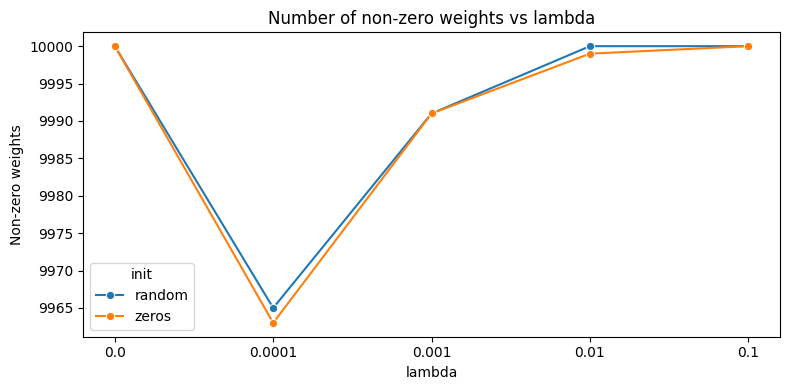

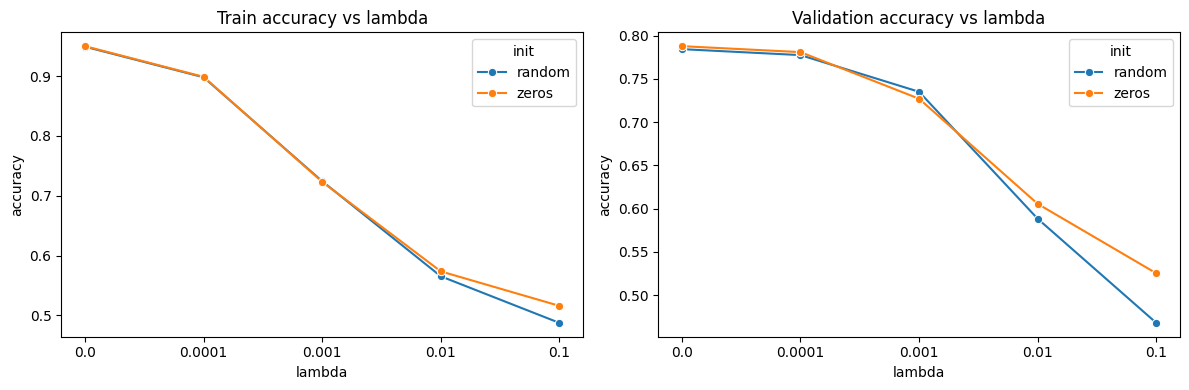

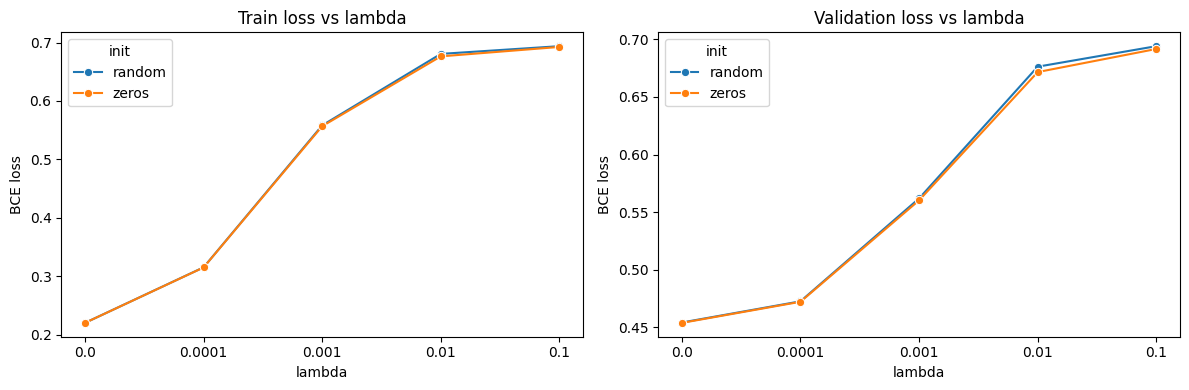

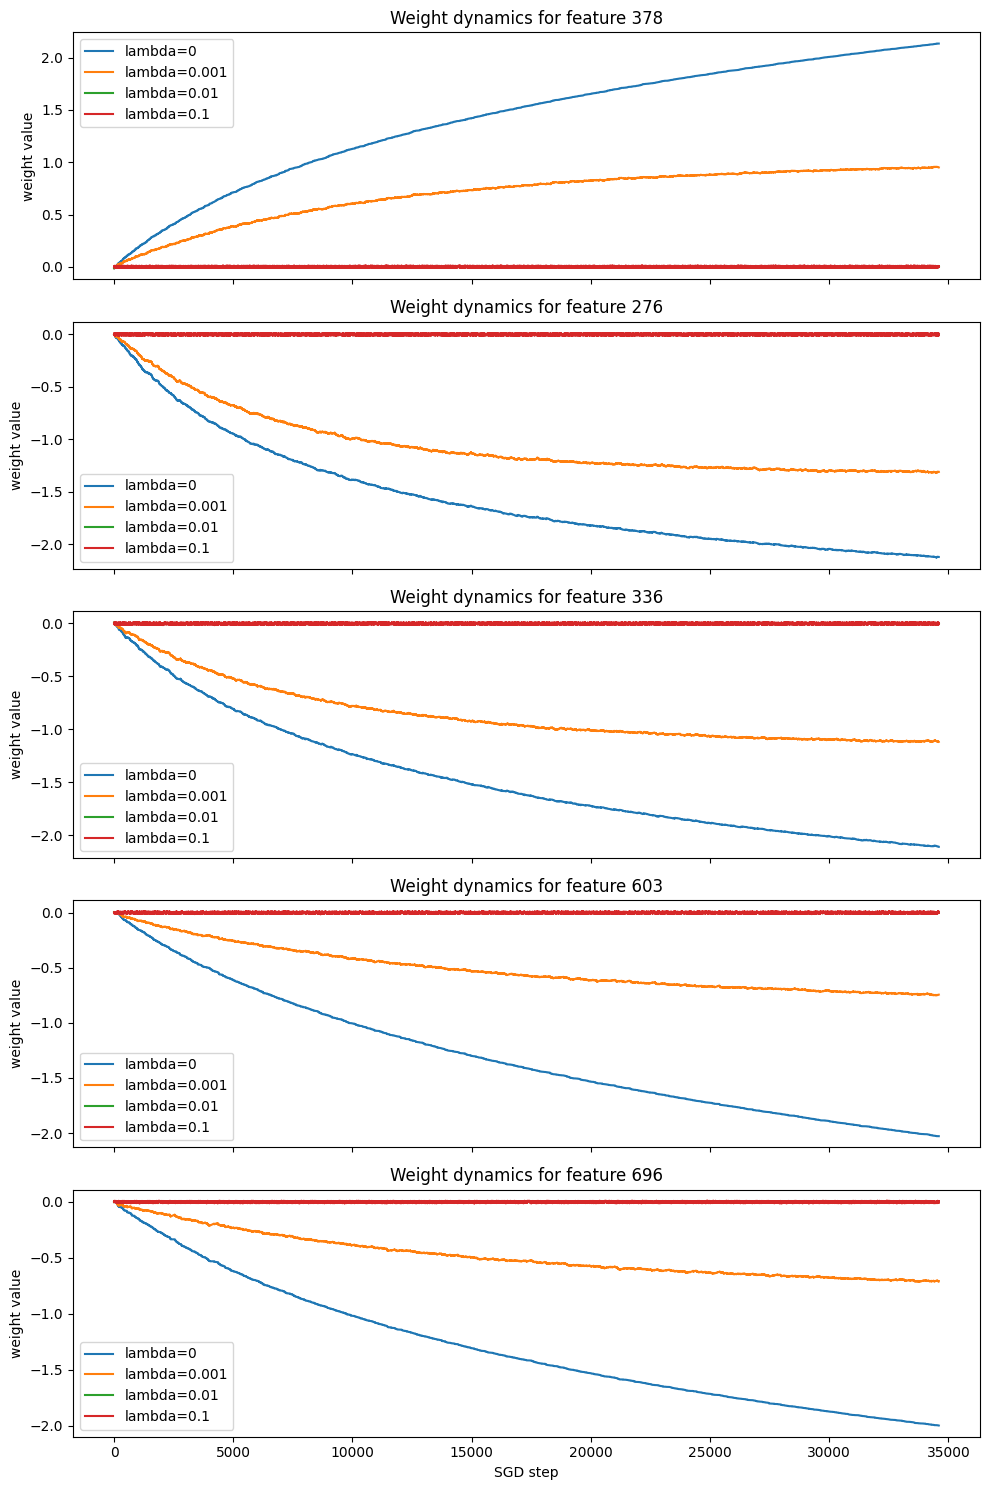

In [14]:
plot_nonzero_vs_lambda(summary_df)
plot_metric_vs_lambda(summary_df, metric_name='accuracy')
plot_loss_vs_lambda(summary_df)

feature_ids = select_eliminated_features(
    final_weights,
    init='random',
    base_lambda=0,
    strong_lambda=1e-1,
    small_tol=1e-7,
    important_tol=1e-3,
    max_features=5
)

plot_weight_dynamics(
    histories,
    feature_ids=feature_ids,
    init='random',
    lambdas=[0, 1e-3, 1e-2, 1e-1]
)

Overall, the experiments show that L1 regularization encourages smaller weights and keeps feature coefficients closer to zero during training.

As $\lambda$ increases, both the training and validation accuracy decrease, while the loss increases. For example, validation accuracy drops from about 0.78 at $\lambda$=0 to around 0.47-0.52 at $\lambda$=0.1, clearly indicating that strong regularization leads to underfitting rather than improving generalization in this setup.

The number of non-zero weights does not decrease in a perfectly monotonic way. For small values such as $\lambda=10^{-4}$ , we see a slight reduction (e.g., from 10000 to ~9960 weights), but for larger values like $\lambda$=0.1, the number of non-zero weights returns to 10000, even though performance degrades. This happens because SGD produces only approximate sparsity. In each update, L1 regularization shifts weights by roughly ±$\alpha$$\lambda$, so instead of reaching exactly zero, small weights tend to oscillate around zero. When this step size is larger than the threshold used to define “zero,” weights remain counted as non-zero, which explains the non-monotonic sparsity pattern.

In contrast, exact sparsity in L1 is typically achieved with optimization methods that include a proximal (soft-thresholding) step, which explicitly pushes small coefficients to zero. Since standard SGD does not include this mechanism, weights remain small but not exactly zero.

Looking at the weight dynamics, larger values of $\lambda$ restrict how much the weights can change, effectively shrinking them toward zero, while smaller values allow them to vary more freely and better fit the data.

Finally, the behavior is very similar for both zero and random initialization. Both reach nearly identical performance (e.g., validation accuracy around 0.78 at $\lambda$=0 and similar degradation as $\lambda$ increases), which is expected since logistic regression is a convex problem, and the optimization converges to the same solution regardless of initialization.

### **Part 2 - Comparing Optimization Algorithms on a Simple vs. Difficult Function (30 pt)**


In this task, you will implement and compare several optimization algorithms on two different mathematical functions.

An optimization algorithm is a method used to update the model's parameters (weights and bias) in order to minimize the loss function.

At each step, it uses the gradients (how the loss changes) to decide:
- in which direction to move
- and how big the update should be

Different optimizers (like SGD, Adam) differ in how they use the gradients and how they control the step size, which affects how fast and how stably the model learns.

The purpose of this task is to help you build intuition for how optimization behaves in:

1. a simple convex function

2. a function with a narrow curved valley

You will implement the following optimizers:

* Gradient Descent (GD)
* Momentum
* AdaGrad
* Adam

Use your optimizers on the following functions:

Function A — Convex bowl:

$f(x,y)= x^2 +4y^2$

This is a simple convex function with a single global minimum.

Function B — the Six-hump Camel function:

$$
\left(4-2.1x^2+\frac{x^4}{3}\right)x^2+xy+\left(-4+4y^2\right)y^2.
$$

This function is much harder to optimize. It has two global minima: $(0.0898, -0.7126)$ and $(-0.0898,0.7126)$, with value about $-1.0316$ - and also several local minina.

Start from at least one non-optimal initial point, for example: (-2, -1.5)


**Task**

For each optimizer and for each function:

1. Initialize the parameters (x,y)
2. repeatedly compute the gradient
3. Update the parameters according to the optimizer rule
4. Record:
  * the function value at each iteration
  * the parameter values $(x_t,y_t)$ at each iteration

**Goal**

Compare how the different optimizers behave on:

* a simple convex function
* a difficult non-convex function

In particular, observe:

* how quickly each optimizer converges
* whether the optimization path is smooth or oscillatory
* whether an optimizer that works well on the convex bowl also works well on Camel
* how the geometry of the function affects the optimization process

**Coding**

Fill in the gaps in the implementation of the optimization method. By the way, you might find this code very repetitive. Can you find a way of shrinking it and getting rid of repetitions?

**Visualization**

Create the following plots:
1. Function value vs. iteration number
2. Optimization trajectories in the (x,y) plane. Use the `plot_trajectories_camel_log` function or create your own function to make an animation/gif.

For each question, please plot the behaviour of all optimization methods on one plot so that you could compare them.

**Analysis**

Summarize your findings in 2-3 text paragraphs. Things to ponder:

* Which optimizer performs best on the convex bowl?
* Which optimizer performs best on the Camel function? Will any of them reliably find global optima or will all of them get trapped in local minina from time to time, depending on the starting point.
* Do the same hyperparameters work equally well for both functions?
* What advantages do Momentum, AdaGrad, and Adam provide compared to plain Gradient Descent?

In [15]:
import torch
import matplotlib.pyplot as plt

# Convex bowl
def bowl(theta):
    x, y = theta[0], theta[1]
    return x**2 + 2*y**2

# Camel function
def camel(theta):
    x, y = theta[0], theta[1]
    return (4 - 2.1 * x**2+ x**4 / 3) * x**2 + x * y + (-4 + 4 * y**2) * y**2


def plot_trajectories_camel_log(f, results, xlim=(-3, 3), ylim=(-2, 2), title="Optimization Trajectories"):
    x_values = np.linspace(xlim[0], xlim[1], 400)
    y_values = np.linspace(ylim[0], ylim[1], 400)
    X, Y = np.meshgrid(x_values, y_values)

    grid = np.stack((X, Y), axis=-1)
    Z = f(torch.tensor(grid, dtype=torch.float32)).detach().numpy()

    plt.figure(figsize=(8, 6))
    plt.contour(X, Y, np.log1p(Z), levels=30)

    for name, (trajectory, _) in results.items():
        plt.plot(trajectory[:, 0], trajectory[:, 1], marker='o', markersize=2, label=name)

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [16]:
def gradient_descent(f, theta0, lr=0.001, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        # TODO: compute loss
        loss = f(theta)

        # TODO: compute gradients
        loss.backward()

        # TODO: update parameters
        with torch.no_grad():
            theta -= lr * theta.grad

        # reset gradients
        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def momentum(f, theta0, lr=0.001, beta=0.9, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    v = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        loss = f(theta)
        loss.backward()

        with torch.no_grad():
            # TODO: update velocity
            v = beta * v + (1 - beta) * theta.grad

            # TODO: update parameters
            theta -= lr * v

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def adagrad(f, theta0, lr=0.1, eps=1e-8, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    G = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(n_steps):
        loss = f(theta)
        loss.backward()

        with torch.no_grad():
            # TODO: accumulate squared gradients
            G += theta.grad ** 2

            # TODO: update parameters
            #theta -= lr * G / (torch.sqrt(G) + eps)
            theta -= lr * theta.grad / (torch.sqrt(G) + eps)

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

def adam(f, theta0, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8, n_steps=2000):
    theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
    m = torch.zeros_like(theta)
    v = torch.zeros_like(theta)

    trajectory = [theta.detach().clone()]
    values = [f(theta).item()]

    for step in range(1, n_steps + 1):
        loss = f(theta)
        loss.backward()

        with torch.no_grad():
            # TODO: update moments
            m = beta1 * m + (1 - beta1) * theta.grad
            v = beta2 * v + (1 - beta2) * (theta.grad ** 2)

            # TODO: bias correction
            m_hat = m / (1 - beta1 ** step)
            v_hat = v / (1 - beta2 ** step)

            # TODO: update parameters
            theta -= lr * m_hat / (torch.sqrt(v_hat) + eps)

        theta.grad.zero_()

        trajectory.append(theta.detach().clone())
        values.append(loss.item())

    return torch.stack(trajectory), values

/tmp/ipykernel_23792/2372652860.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
/tmp/ipykernel_23792/2372652860.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
/tmp/ipykernel_23792/2372652860.py:52: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta = torch.tensor(theta0, dtype=torch.float32, requires_grad=True)
/tmp/ipykernel_23792/2372652860.py:78: UserWarning: To copy construct from a ten

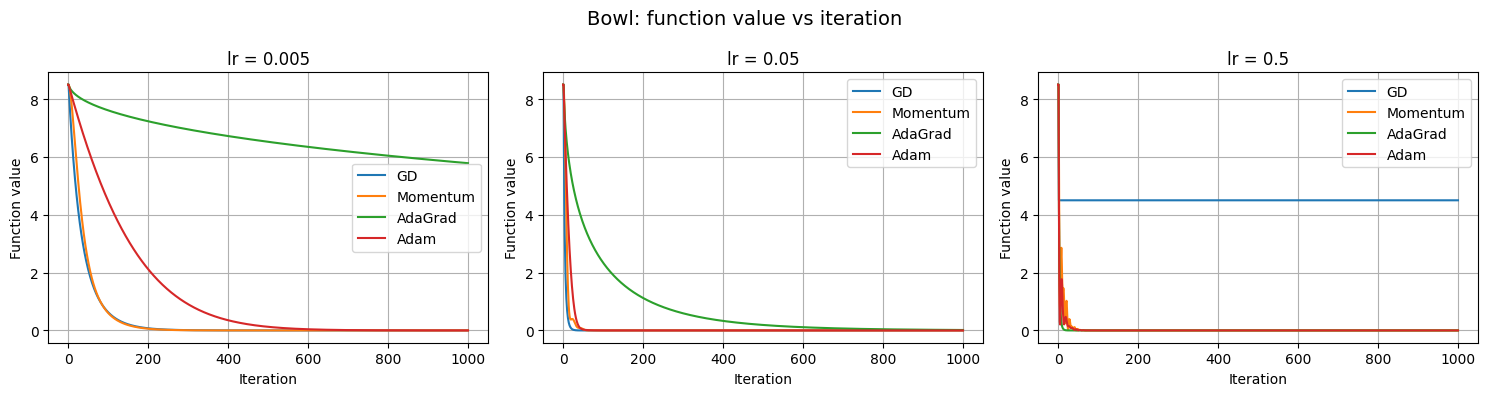

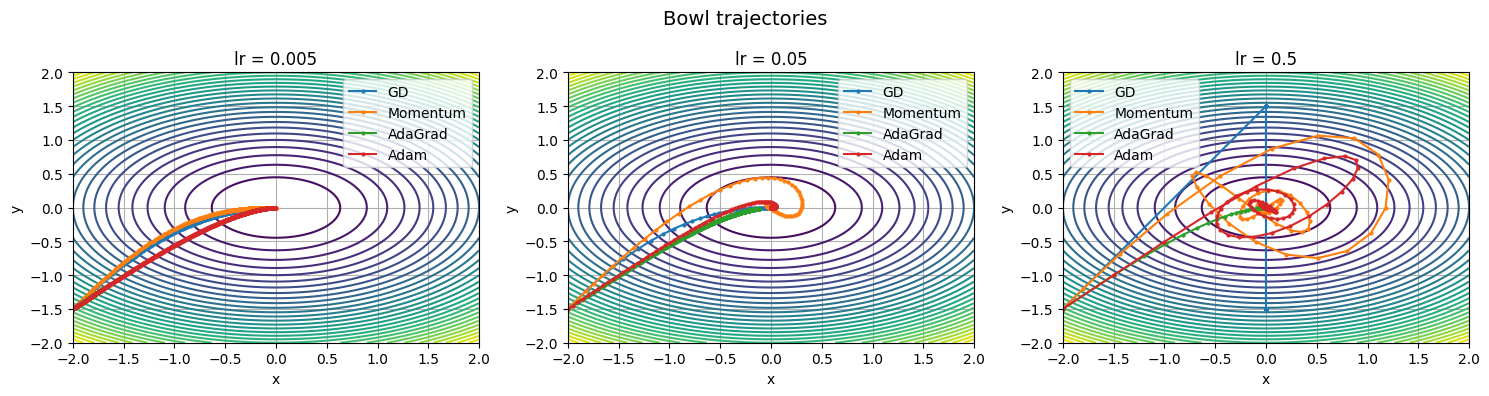

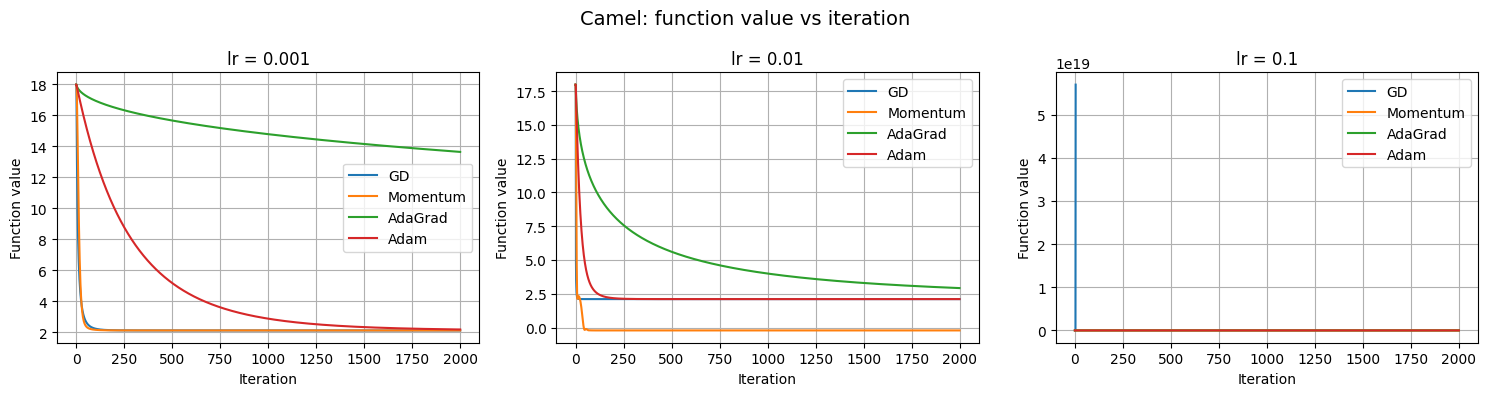

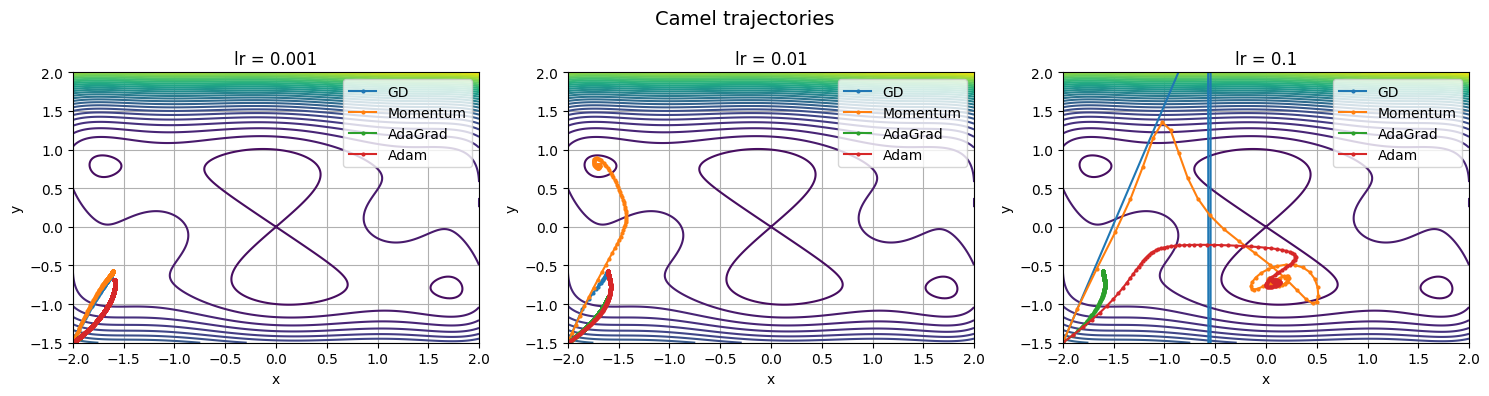

In [17]:
#Run experiments

def run_all_optimizers_for_lrs(f, theta0, lrs, n_steps=500, momentum_beta=0.9):
    results = {}

    for lr in lrs:
        results[lr] = {
            "GD": gradient_descent(f, theta0, lr=lr, n_steps=n_steps),
            "Momentum": momentum(f, theta0, lr=lr, beta=momentum_beta, n_steps=n_steps),
            "AdaGrad": adagrad(f, theta0, lr=lr, n_steps=n_steps),
            "Adam": adam(f, theta0, lr=lr, n_steps=n_steps),
        }

    return results

def plot_values_by_lr(results, title):
    lrs = list(results.keys())
    n = len(lrs)

    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4), squeeze=False)
    axes = axes[0]

    for ax, lr in zip(axes, lrs):
        for opt_name, (_, values) in results[lr].items():
            ax.plot(values, label=opt_name)

        ax.set_title(f"lr = {lr}")
        ax.set_xlabel("Iteration")
        ax.set_ylabel("Function value")
        ax.grid(True)
        ax.legend()

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

def make_contour_data(f, xlim=(-2, 2), ylim=(-2, 2), n=300):
    xs = np.linspace(xlim[0], xlim[1], n)
    ys = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(xs, ys)

    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            theta = torch.tensor([X[i, j], Y[i, j]], dtype=torch.float32)
            Z[i, j] = f(theta).item()

    return X, Y, Z

def plot_trajectories_by_lr(results, f, xlim=(-2, 2), ylim=(-2, 2), title="Trajectories"):
    lrs = list(results.keys())
    n = len(lrs)

    X, Y, Z = make_contour_data(f, xlim=xlim, ylim=ylim, n=250)

    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4), squeeze=False)
    axes = axes[0]

    for ax, lr in zip(axes, lrs):
        ax.contour(X, Y, Z, levels=30)

        for opt_name, (trajectory, _) in results[lr].items():
            traj = trajectory.detach().numpy()
            ax.plot(traj[:, 0], traj[:, 1], marker='o', markersize=2, label=opt_name)

        ax.set_title(f"lr = {lr}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.grid(True)
        ax.legend()

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

theta0 = torch.tensor([-2, -1.5], dtype=torch.float32)

bowl_lrs = [0.005, 0.05, 0.5]
results_bowl_by_lr = run_all_optimizers_for_lrs(
    bowl, theta0, lrs=bowl_lrs, n_steps=1000
)

plot_values_by_lr(results_bowl_by_lr, "Bowl: function value vs iteration")
plot_trajectories_by_lr(
    results_bowl_by_lr,
    bowl,
    xlim=(-2, 2),
    ylim=(-2, 2),
    title="Bowl trajectories"
)

camel_lrs = [0.001, 0.01, 0.1]
results_camel_by_lr = run_all_optimizers_for_lrs(
    camel, theta0, lrs=camel_lrs, n_steps=2000
)

plot_values_by_lr(results_camel_by_lr, "Camel: function value vs iteration")
plot_trajectories_by_lr(
    results_camel_by_lr,
    camel,
    xlim=(-2, 2),
    ylim=(-1.5, 2),
    title="Camel trajectories"
)


**Analysis**

For the convex bowl function, Gradient Descent and Momentum performed best at small learning rates in my experiments. Both converged quickly and stably to the minimum. Adam also reached the optimum, but it converged more slowly. AdaGrad performed worse with the same small learning rate because its effective step size became too small, so it did not converge within the same number of iterations. When I increased the learning rate, all optimizers converged, although AdaGrad was still slightly slower at first. At the largest learning rate, plain Gradient Descent became unstable and got stuck at a suboptimal value, while the other optimizers still reached the optimum. In this setting, AdaGrad even converged faster than the others.

For the Camel function, the results depended strongly on the starting point and the learning rate. In my experiments, Momentum and Adam performed better and more often converged to the global minimum. However, none of the optimizers found the global optimum reliably from every initialization. When the starting point was close to a local minimum and the learning rate was small, all methods got trapped there. This behavior is explained by the non-convex structure of the Camel function, which contains multiple local minima and saddle points. AdaGrad tends to get stuck in these regions because its effective learning rate decreases over time, making it difficult to escape once it slows down. Momentum, on the other hand, can sometimes overshoot shallow minima due to accumulated gradients, which helps it escape in some cases but also makes its behavior sensitive to the starting point. Adam combines both momentum and adaptive scaling, which explains why it is generally more robust across different initializations.

These results show that the same hyperparameters do not work equally well for both functions. Compared to plain Gradient Descent, Momentum improved convergence speed but sometimes caused strong oscillations at the beginning, AdaGrad was more stable but slower at small learning rates and less effective at escaping poor regions, and Adam was the most robust on the more difficult initializations, although it was not always the fastest optimizer.

In some runs on the Camel function, especially with larger learning rates, I also observed divergence or highly unstable behavior, where the loss increased instead of decreasing. This highlights the sensitivity of non-convex problems to hyperparameters, where too large step sizes can cause the optimizer to overshoot minima or move chaotically between regions.

While the conclusions above are based on observed behavior in the trajectories, a more complete comparison could include a quantitative table (e.g., final loss values or number of iterations to convergence) to better compare convergence speed and stability across optimizers.